In [1]:
#Import library
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans

In [2]:
from pathlib import Path

def data_path(name):
    """Resolve a file in the project's data/ directory from any depth."""
    d = Path.cwd()
    for _ in range(5):
        if (d / "data" / name).exists():
            return d / "data" / name
        d = d.parent
    raise FileNotFoundError(f"data/{name} not found above {Path.cwd()}")

#Upload file excel
filedata = data_path("penguins.csv")
readexcel = pd.read_csv(filedata)
df= pd.DataFrame(readexcel)
df.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
3,NaN,NaN,NaN,NaN,NaN
4,36.7,19.3,193.0,3450.0,FEMALE


In [3]:
#Preprocessing
#Drop data null
df_clean = df.dropna()
#Encoding sex (male:1 female: 0)
le = LabelEncoder()
df_clean['sex'] = le.fit_transform(df_clean['sex'])
#Standarisasi
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_clean)
#PCA
pca = PCA(n_components=2)
df_pca = pca.fit_transform(df_scaled)

<tmp>\ipykernel_12676\718682733.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['sex'] = le.fit_transform(df_clean['sex'])


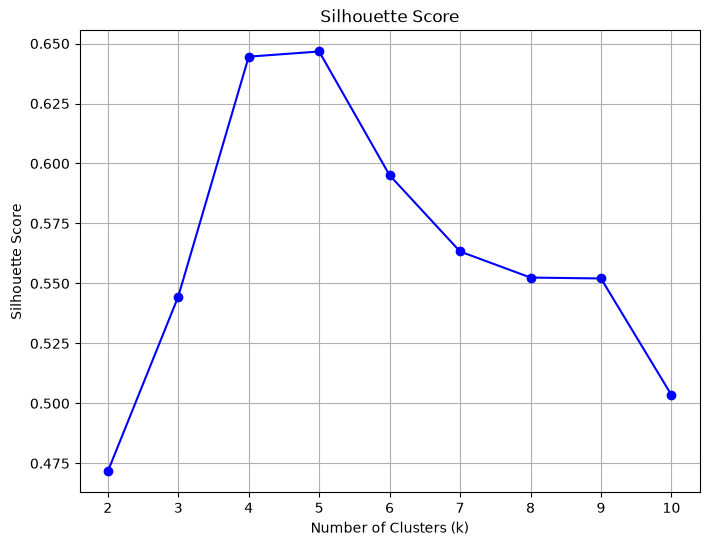

K terbaik: 5


In [4]:
#silhoutte score
silhouette_scores = []
k_values = list(range(2, 11))
for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42)
    cluster_labels = kmeans.fit_predict(df_pca)
    silhouette_avg = silhouette_score(df_pca, cluster_labels)
    silhouette_scores.append(silhouette_avg)
#Visualisasi
plt.figure(figsize=(8, 6))
plt.plot(k_values, silhouette_scores, marker='o', linestyle='-', color='b')
plt.title('Silhouette Score')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.xticks(k_values)
plt.grid(True)
plt.show()
#Best K
best_k = k_values[silhouette_scores.index(max(silhouette_scores))]
print(f"K terbaik: {best_k}")

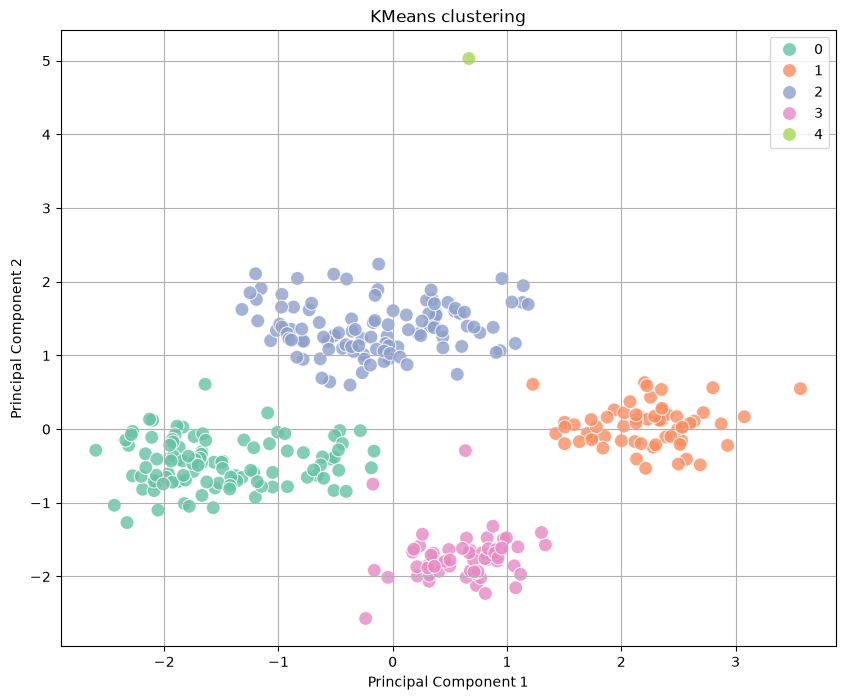

In [5]:
#Kmeans
kmeans = KMeans(n_clusters=best_k, random_state=42)
cluster_labels = kmeans.fit_predict(df_pca)
#Visualisasi
plt.figure(figsize=(10, 8))
sns.scatterplot(x=df_pca[:, 0], y=df_pca[:, 1], hue=cluster_labels, palette="Set2", s=100, alpha=0.8)
plt.title(f'KMeans clustering')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.grid(True)
plt.show()